# Pronóstico del consumo eléctrico de Tetuán a una hora

**TB1 · Metodología para Data Science (1ACC0240) · UPC · ciclo 2026-2 · Grupo 3**

Notebook 02 de CRISP-DM: **modelado y evaluación**. Parte del dataset del
[notebook 01](01_datos_preparacion.ipynb) y del criterio de éxito de
[`docs/negocio.md`](https://github.com/R0SEWT/tetouan-power-forecast/blob/develop/docs/negocio.md#8-criterios-de-éxito):
el MAE del modelo tiene que quedar por debajo del de la **mejor de las tres referencias ingenuas** de cada zona
(persistencia, ayer y semana pasada a la misma hora), en la validación de origen móvil y en la prueba final, y
también en las horas pico (19 a 22 h).

El notebook 01 mostró el punto débil del modelo en nivel: con un solo año de datos, los árboles no extrapolan a
los niveles del verano y el calendario anual funciona como identificador de época. La investigación de
[`docs/historico.md`](https://github.com/R0SEWT/tetouan-power-forecast/blob/develop/docs/historico.md) propone
pronosticar la **razón** entre el consumo en t+6 y la media de las últimas 24 h, y un **modelo global** de las
tres zonas. Aquí se comparan contra las referencias ingenuas y contra el modelo del notebook 01.

| Paso | Qué hace |
|---|---|
| 1. Datos y partición | Las variables en razón de cada zona y la partición 70/15/15 del notebook 01 |
| 2. Referencias ingenuas | La vara que el modelo tiene que superar en cada zona |
| 3. Qué objetivo aprender | Nivel, cambio o razón, con el mismo algoritmo |
| 4. Algoritmos y búsqueda de hiperparámetros | Ridge, Random Forest y Gradient Boosting con validación cruzada temporal |
| 5. Modelo global | Un solo modelo para las tres zonas frente a uno por zona |
| 6. Elección del modelo | Contra la mejor referencia de cada zona, en la validación |
| 7. Origen móvil mensual | Cómo se comporta mes a mes, incluido el verano que no vio |
| 8. Prueba final | Noviembre y diciembre, que no se tocan hasta aquí |
| 9. Errores desagregados | Por hora, día de la semana, feriados, Ramadán y la transferencia del 25 de octubre |
| 10. Diagnóstico | Real contra predicho y residuos |
| 11. Importancia de variables | Por permutación, en la validación |
| 12. Modelo final | Se guarda en el Drive para la app |

Corre en Colab en unos 20 a 30 minutos (la búsqueda de hiperparámetros es lo más lento).

# Configuración

En Colab se instala el código del repo y se monta Google Drive, donde viven las capas del medallón (las arma el
notebook `00_medallon`). En local se usan las capas de `data/`.

In [1]:
import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAMA = "develop"  # rama del repo desde la que se instala el código
    !pip install -q "git+https://github.com/R0SEWT/tetouan-power-forecast@{RAMA}"

In [2]:
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from tetouan_power_forecast import HORIZONTE
from tetouan_power_forecast.datos import columnas_predictoras, nombre_objetivo
from tetouan_power_forecast.evaluacion import (
    HORAS_PICO,
    bootstrap_diferencia_mae,
    errores,
    hora_objetivo,
    mae_por_grupo,
    plegados_mensuales,
    subestimacion_pico,
)
from tetouan_power_forecast.medallon import cargar_gold, cargar_silver, raiz_datos, usar_drive
from tetouan_power_forecast.modelos import CVPorFecha, ModeloDelta, ModeloRazon
from tetouan_power_forecast.variables import REFERENCIAS, columnas_modelo, dataset_global, dataset_razon

if EN_COLAB:
    usar_drive()  # Mi unidad/datalake/tetouan-power-forecast
else:
    os.environ.setdefault("TETOUAN_DATA", str(Path.cwd().parent / "data"))  # el notebook corre desde notebooks/

SEMILLA = 0
N_FOLDS = 5  # validación cruzada temporal de la búsqueda de hiperparámetros
ITERACIONES = {"Random Forest": 8, "Gradient Boosting": 20, "Global": 10}  # combinaciones probadas
ZONAS = [1, 2, 3]
NOMBRES = {1: "Zona 1", 2: "Zona 2", 3: "Zona 3"}
NOMBRES_REF = {"persistencia": "Persistencia", "ayer": "Ayer", "semana_pasada": "Semana pasada"}
COLORES = {1: "royalblue", 2: "darkorange", 3: "seagreen"}
pd.set_option("display.width", 160)

# Modelado

## 1. Datos y partición

Cada zona tiene su dataset con las **variables en razón** (`dataset_razon`, en `src/tetouan_power_forecast/variables.py`):

- **Consumo relativo:** el consumo de la zona en t, t−1, t−2 y t−6, el de ayer y el de la semana pasada a la
  hora de t+6, y la media y la desviación de la última hora, todo dividido por la media de las últimas 24 h de la
  zona (`Zona_*`). Las otras dos zonas entran igual, divididas por su propia media (`Zone2_*`, `Zone3_*`).
- **Nivel reciente:** la media de 24 h sobre la de 7 días (`Zona_m24_vs_m7d`): si el último día viene más alto
  o más bajo que la semana.
- **Calendario diario y semanal**, sin calendario anual. **Feriado** y **Ramadán** de la fecha de t+6, que se
  conocen de antemano.
- **Clima en t** y la temperatura media de 24 h. Nada del clima de t+6.

El modelo aprende `consumo(t+6) / media_24h(t)` y la predicción se multiplica por `media_24h` para volver a kW.
Las métricas siempre se calculan en kW.

La primera semana del año queda fuera (hace falta para el rezago semanal). La partición es la del notebook 01:
70/15/15 cronológica, con un hueco de 6 periodos antes de cada corte para que ningún objetivo de entrenamiento
caiga en validación ni uno de validación en prueba.

In [3]:
silver = cargar_silver()
gold = cargar_gold(zona=1)  # el dataset del notebook 01, para el modelo en nivel
locales = {z: dataset_razon(silver, zona=z) for z in ZONAS}
global_ = dataset_global(silver)

# La partición del gold (70/15/15 con hueco) se lleva a cada dataset por fecha
particion = gold.set_index("DateTime")["particion"].astype(str)
for datos in [*locales.values(), global_]:
    datos["particion"] = datos["DateTime"].map(particion)
    assert datos["particion"].notna().all()
for z in ZONAS:  # el modelo global y los modelos por zona predicen las mismas filas
    assert (global_.loc[global_["zona"] == z, "DateTime"].to_numpy() == locales[z]["DateTime"].to_numpy()).all()

INICIO_PRUEBA = gold.loc[gold["particion"] == "prueba", "DateTime"].min()
FIN_DESARROLLO = INICIO_PRUEBA - pd.Timedelta(minutes=10 * HORIZONTE)  # entrenamiento final: hasta aquí


def tramo(datos, nombre):
    if nombre == "desarrollo":  # entrenamiento + validación, para el modelo final
        return datos[datos["DateTime"] < FIN_DESARROLLO]
    return datos[datos["particion"] == nombre]


resumen = pd.DataFrame({
    nombre: {"Filas": len(d), "Desde": d["DateTime"].min(), "Hasta": d["DateTime"].max()}
    for nombre in ["entrenamiento", "validacion", "prueba"] for d in [tramo(locales[1], nombre)]
}).T
display(resumen)
print("Variables de la Zona 1:", len(columnas_modelo(locales[1])) - 1, "+ la media de 24 h")
print("Variables del modelo global:", len(columnas_modelo(global_)) - 1, "+ la media de 24 h (con la zona como categórica)")

,Filas,Desde,Hasta
entrenamiento,35714,2017-01-08 00:00:00,2017-09-13 00:10:00
validacion,7835,2017-09-13 01:20:00,2017-11-06 11:00:00
prueba,7841,2017-11-06 12:10:00,2017-12-30 22:50:00


Variables de la Zona 1: 34 + la media de 24 h
Variables del modelo global: 27 + la media de 24 h (con la zona como categórica)


## 2. Referencias ingenuas

Son la vara que el modelo tiene que superar. Se calculan en la validación; en la prueba se miran recién al final.

In [4]:
def tabla_referencias(nombre_tramo):
    filas = []
    for z, datos in locales.items():
        d = tramo(datos, nombre_tramo)
        for ref in REFERENCIAS:
            filas.append({"Zona": NOMBRES[z], "Referencia": NOMBRES_REF[ref], **errores(d["real"], d[ref])})
    return pd.DataFrame(filas).set_index(["Zona", "Referencia"])


def mejor_referencia(datos):
    return min(REFERENCIAS, key=lambda ref: errores(datos["real"], datos[ref])["MAE (kW)"])


referencias_val = tabla_referencias("validacion")
display(referencias_val.round(2))
MEJOR_REF_VAL = {z: mejor_referencia(tramo(locales[z], "validacion")) for z in ZONAS}
print("Mejor referencia en la validación:", {NOMBRES[z]: NOMBRES_REF[r] for z, r in MEJOR_REF_VAL.items()})

MAE (kW)  RMSE (kW)  MAPE (%)
Zona   Referencia                                  
Zona 1 Persistencia    2074.52    2905.38      6.25
       Ayer            1159.63    1643.66      3.64
       Semana pasada   1442.69    1979.86      4.56
Zona 2 Persistencia    1382.08    1912.21      6.45
       Ayer            1322.20    1913.13      6.49
       Semana pasada   1199.98    1664.66      5.50
Zona 3 Persistencia    1005.12    1516.94      7.51
       Ayer             594.71     857.44      4.63
       Semana pasada    855.78    1111.00      6.62

Mejor referencia en la validación: {'Zona 1': 'Ayer', 'Zona 2': 'Semana pasada', 'Zona 3': 'Ayer'}


## 3. Qué objetivo aprender: nivel, cambio o razón

Con el mismo algoritmo del notebook 01 (`HistGradientBoostingRegressor` sin ajustar), entrenado con la partición
de entrenamiento de la Zona 1 y evaluado en la validación:

- **Nivel:** el consumo en t+6, con las variables del notebook 01 (incluido el calendario anual).
- **Cambio:** el consumo en t+6 menos el de t (`ModeloDelta`), con las mismas variables.
- **Razón:** el consumo en t+6 sobre la media de 24 h (`ModeloRazon`), con las variables en razón.

In [5]:
def hgb_notebook_01():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, early_stopping=False,
                                         random_state=SEMILLA)


z1 = locales[1]
tr1, va1 = tramo(z1, "entrenamiento"), tramo(z1, "validacion")
COLS_RAZON = columnas_modelo(z1)
g_tr, g_va = gold[gold["particion"] == "entrenamiento"], gold[gold["particion"] == "validacion"]
COLS_GOLD, Y_GOLD = columnas_predictoras(gold), nombre_objetivo(1)
assert (g_va["DateTime"].to_numpy() == va1["DateTime"].to_numpy()).all()  # las mismas filas de validación

predicciones_objetivo = {
    "Nivel (notebook 01)": hgb_notebook_01().fit(g_tr[COLS_GOLD], g_tr[Y_GOLD]).predict(g_va[COLS_GOLD]),
    "Cambio respecto de t": ModeloDelta(hgb_notebook_01(), "Zone1_t")
        .fit(g_tr[COLS_GOLD], g_tr[Y_GOLD]).predict(g_va[COLS_GOLD]),
    "Razón con la media de 24 h": ModeloRazon(hgb_notebook_01()).fit(tr1[COLS_RAZON], tr1["real"]).predict(va1[COLS_RAZON]),
    f"Mejor referencia ({NOMBRES_REF[MEJOR_REF_VAL[1]]})": va1[MEJOR_REF_VAL[1]].to_numpy(),
}
tabla_objetivo = pd.DataFrame({k: errores(va1["real"], p) for k, p in predicciones_objetivo.items()}).T
mae_ref = tabla_objetivo["MAE (kW)"].iloc[-1]
tabla_objetivo["Mejora vs. mejor referencia (%)"] = 100 * (1 - tabla_objetivo["MAE (kW)"] / mae_ref)
display(tabla_objetivo.round(2))

,MAE (kW),RMSE (kW),MAPE (%),Mejora vs. mejor referencia (%)
Nivel (notebook 01),738.52,1015.25,2.38,36.31
Cambio respecto de t,793.63,1172.15,2.47,31.56
Razón con la media de 24 h,613.37,870.51,1.90,47.11
Mejor referencia (Ayer),1159.63,1643.66,3.64,0.00


## 4. Algoritmos y búsqueda de hiperparámetros

Se comparan tres familias de algoritmos, todas con el objetivo en razón y sobre la Zona 1:

- **Ridge:** regresión lineal con regularización L2 (con las variables estandarizadas). Es la referencia simple:
  si las variables en razón ya dicen casi todo, un modelo lineal debería andar bien.
- **Random Forest:** promedio de árboles entrenados con muestras distintas; capta no linealidades e
  interacciones (por ejemplo, hora × día de la semana).
- **Gradient Boosting** (`HistGradientBoostingRegressor`): árboles que corrigen los errores de los anteriores;
  suele ser el más preciso en datos tabulares y es rápido con muchas filas.

Los hiperparámetros se buscan con **validación cruzada temporal** (`TimeSeriesSplit` con 5 folds y un hueco de 6
periodos) **solo sobre la partición de entrenamiento**, minimizando el MAE en kW. Ridge tiene un solo
hiperparámetro y se busca en una grilla; los otros dos, con búsqueda aleatoria. La validación queda para comparar
los modelos ya ajustados.

No hay desbalance que tratar: es una regresión. Su equivalente, que los picos pesen poco en el error medio, se
revisa aparte con el error en horas pico y la subestimación de los picos.

In [6]:
cv = TimeSeriesSplit(n_splits=N_FOLDS, gap=HORIZONTE)
candidatos = {
    "Ridge": (
        ModeloRazon(make_pipeline(StandardScaler(), Ridge())),
        {"estimador__ridge__alpha": np.logspace(-3, 3, 13)},
    ),
    "Random Forest": (
        ModeloRazon(RandomForestRegressor(n_jobs=-1, random_state=SEMILLA)),
        {
            "estimador__n_estimators": [100, 200, 300],
            "estimador__max_depth": [None, 12, 20],
            "estimador__min_samples_leaf": [1, 5, 20],
            "estimador__max_features": [0.3, 0.5, 1.0],
            "estimador__max_samples": [0.5, 0.8],
        },
    ),
    "Gradient Boosting": (
        ModeloRazon(HistGradientBoostingRegressor(early_stopping=False, random_state=SEMILLA)),
        {
            "estimador__learning_rate": loguniform(0.02, 0.2),
            "estimador__max_iter": [200, 300, 500, 800],
            "estimador__max_leaf_nodes": [15, 31, 63],
            "estimador__min_samples_leaf": [20, 50, 100],
            "estimador__l2_regularization": [0.0, 0.1, 1.0],
        },
    ),
}

busquedas, filas = {}, []
for nombre, (modelo, espacio) in candidatos.items():
    if nombre in ITERACIONES:
        busqueda = RandomizedSearchCV(modelo, espacio, n_iter=ITERACIONES[nombre], cv=cv,
                                      scoring="neg_mean_absolute_error", random_state=SEMILLA)
    else:
        busqueda = GridSearchCV(modelo, espacio, cv=cv, scoring="neg_mean_absolute_error")
    inicio = time.time()
    busqueda.fit(tr1[COLS_RAZON], tr1["real"])
    busquedas[nombre] = busqueda
    i = busqueda.best_index_
    filas.append({
        "Algoritmo": nombre,
        "Combinaciones": len(busqueda.cv_results_["params"]),
        "MAE CV (kW)": -busqueda.best_score_,
        "Desv. entre folds (kW)": busqueda.cv_results_["std_test_score"][i],
        "Minutos": (time.time() - inicio) / 60,
        "Mejores hiperparámetros": {k.split("__")[-1]: (round(v, 4) if isinstance(v, float) else v)
                                    for k, v in busqueda.best_params_.items()},
    })
    print(f"{nombre}: listo en {(time.time() - inicio) / 60:.1f} min", flush=True)

tabla_busqueda = pd.DataFrame(filas).set_index("Algoritmo")
display(tabla_busqueda.round(2))

Ridge: listo en 0.0 min


Random Forest: listo en 2.5 min


Gradient Boosting: listo en 7.3 min


,Combinaciones,MAE CV (kW),Desv. entre folds (kW),Minutos,Mejores hiperparámetros
Algoritmo,,,,,
Ridge,13,755.97,88.55,0.04,{'alpha': 0.001}
Random Forest,8,867.12,225.11,2.47,"{'n_estimators': 300, 'min_samples_leaf': 5, '..."
Gradient Boosting,20,879.65,181.79,7.35,"{'l2_regularization': 0.1, 'learning_rate': 0...."


Cada algoritmo, con sus mejores hiperparámetros y reentrenado con toda la partición de entrenamiento, se evalúa en
la validación de la Zona 1:

In [7]:
predicciones_val_z1 = {nombre: b.best_estimator_.predict(va1[COLS_RAZON]) for nombre, b in busquedas.items()}
predicciones_val_z1[f"Mejor referencia ({NOMBRES_REF[MEJOR_REF_VAL[1]]})"] = va1[MEJOR_REF_VAL[1]].to_numpy()
tabla_algoritmos = pd.DataFrame({k: errores(va1["real"], p) for k, p in predicciones_val_z1.items()}).T
tabla_algoritmos["Mejora vs. mejor referencia (%)"] = 100 * (1 - tabla_algoritmos["MAE (kW)"] / tabla_algoritmos["MAE (kW)"].iloc[-1])
display(tabla_algoritmos.round(2))

,MAE (kW),RMSE (kW),MAPE (%),Mejora vs. mejor referencia (%)
Ridge,634.52,913.31,1.94,45.28
Random Forest,628.77,907.54,1.96,45.78
Gradient Boosting,604.34,865.23,1.87,47.88
Mejor referencia (Ayer),1159.63,1643.66,3.64,0.00


## 5. Modelo global de las tres zonas

En vez de un modelo por zona, un solo modelo aprende de las tres zonas apiladas, con la zona como variable
categórica y solo las variables de la propia zona. Como el objetivo y las variables están en razón, las tres
zonas hablan "el mismo idioma" y el modelo ve tres veces más ejemplos de cada situación (por ejemplo, de cada
hora de un domingo de verano). Es la estrategia de Montero-Manso y Hyndman (2021) para series cortas.

Sus hiperparámetros se buscan con la misma validación cruzada temporal, ahora sobre las fechas (`CVPorFecha`):
las tres zonas de una misma fecha quedan siempre del mismo lado.

In [8]:
COLS_GLOBAL = columnas_modelo(global_)
tr_g = tramo(global_, "entrenamiento")
espacio_hgb = candidatos["Gradient Boosting"][1]
busqueda_global = RandomizedSearchCV(
    ModeloRazon(HistGradientBoostingRegressor(early_stopping=False, random_state=SEMILLA,
                                              categorical_features=["zona"])),
    espacio_hgb, n_iter=ITERACIONES["Global"], cv=CVPorFecha(n_splits=N_FOLDS, gap=HORIZONTE),
    scoring="neg_mean_absolute_error", random_state=SEMILLA,
)
inicio = time.time()
busqueda_global.fit(tr_g[COLS_GLOBAL], tr_g["real"], groups=tr_g["DateTime"])
print(f"Búsqueda del modelo global: {(time.time() - inicio) / 60:.1f} min")
print("MAE CV (kW, las tres zonas):", round(-busqueda_global.best_score_, 1))
print("Mejores hiperparámetros:", {k.split("__")[-1]: (round(v, 4) if isinstance(v, float) else v)
                                   for k, v in busqueda_global.best_params_.items()})

Búsqueda del modelo global: 4.1 min
MAE CV (kW, las tres zonas): 646.7
Mejores hiperparámetros: {'l2_regularization': 0.0, 'learning_rate': np.float64(0.021), 'max_iter': 800, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}


## 6. Elección del modelo

Se comparan en la validación de las tres zonas:

- los tres algoritmos **por zona**, con los hiperparámetros que ganaron en la Zona 1 (buscarlos zona por zona
  triplicaría el tiempo y arriesga sobreajustar la validación cruzada);
- el **modelo global**;
- la **mejor referencia ingenua** de cada zona.

Para elegir, se usa la mejora del MAE frente a la mejor referencia de cada zona, promediada entre las tres: es lo
que pide el criterio de éxito, y no favorece a la zona con más consumo.

In [9]:
def modelo_local(nombre):
    return busquedas[nombre].best_estimator_  # se clona en cada ajuste


def predecir_locales(nombre, entrenar, evaluar):
    # Ajusta un modelo por zona con las filas de `entrenar` y predice las de `evaluar`
    salida = {}
    for z, datos in locales.items():
        tr, te = entrenar(datos), evaluar(datos)
        cols = columnas_modelo(datos)
        salida[z] = clone(modelo_local(nombre)).fit(tr[cols], tr["real"]).predict(te[cols])
    return salida


def predecir_global(modelo, entrenar, evaluar):
    tr, te = entrenar(global_), evaluar(global_)
    pred = clone(modelo).fit(tr[COLS_GLOBAL], tr["real"]).predict(te[COLS_GLOBAL])
    return {z: pred[(te["zona"] == z).to_numpy()] for z in ZONAS}


def en(nombre):
    return lambda datos: tramo(datos, nombre)


candidatos_val = {f"{nombre} por zona": predecir_locales(nombre, en("entrenamiento"), en("validacion"))
                  for nombre in busquedas}
candidatos_val["Gradient Boosting global"] = predecir_global(busqueda_global.best_estimator_,
                                                             en("entrenamiento"), en("validacion"))

filas = []
for metodo, por_zona in [*candidatos_val.items(), ("Mejor referencia", None)]:
    for z in ZONAS:
        va = tramo(locales[z], "validacion")
        pred = va[MEJOR_REF_VAL[z]].to_numpy() if por_zona is None else por_zona[z]
        e = errores(va["real"], pred)
        mae_ref = errores(va["real"], va[MEJOR_REF_VAL[z]])["MAE (kW)"]
        filas.append({"Método": metodo, "Zona": NOMBRES[z], "MAE (kW)": e["MAE (kW)"], "MAPE (%)": e["MAPE (%)"],
                      "Mejora vs. mejor referencia (%)": 100 * (1 - e["MAE (kW)"] / mae_ref)})
comparacion_val = pd.DataFrame(filas)
display(comparacion_val.pivot(index="Método", columns="Zona").round(2))

mejora_media = (comparacion_val[comparacion_val["Método"] != "Mejor referencia"]
                .groupby("Método")["Mejora vs. mejor referencia (%)"].mean().sort_values(ascending=False))
print("Mejora media frente a la mejor referencia (%):")
print(mejora_media.round(1).to_string())
ELEGIDO = mejora_media.index[0]
print("\nModelo elegido:", ELEGIDO)

MAE (kW)                  MAPE (%)               Mejora vs. mejor referencia (%)              
Zona                         Zona 1   Zona 2  Zona 3   Zona 1 Zona 2 Zona 3                          Zona 1 Zona 2 Zona 3
Método                                                                                                                   
Gradient Boosting global     590.07   472.70  373.06     1.82   2.25   2.86                           49.12  60.61  37.27
Gradient Boosting por zona   604.34   483.12  375.60     1.87   2.28   2.91                           47.88  59.74  36.84
Mejor referencia            1159.63  1199.98  594.71     3.64   5.50   4.63                            0.00   0.00   0.00
Random Forest por zona       628.77   491.59  381.64     1.96   2.31   2.95                           45.78  59.03  35.83
Ridge por zona               634.52   462.51  369.35     1.94   2.16   2.83                           45.28  61.46  37.89

Mejora media frente a la mejor referencia (%):
Método
Gradient Boosting global      49.0
Ridge por zona                48.2
Gradient Boosting por zona    48.2
Random Forest por zona        46.9

Modelo elegido: Gradient Boosting global


# Evaluación

El modelo elegido se evalúa en tres pasos: con **origen móvil mensual** sobre entrenamiento y validación (¿le gana a
la mejor referencia todos los meses?), en la **prueba** de noviembre y diciembre, y **desagregado** por hora, día
de la semana, feriados, Ramadán y la transferencia de carga del 25 de octubre.

Para no depender de una sola elección, el origen móvil y la prueba se corren también con el Gradient Boosting por
zona, que es la alternativa más cercana.

In [10]:
def ajustar_y_predecir(metodo, entrenar, evaluar):
    # Predicciones por zona de un método (por zona o global) entrenado y evaluado en las filas indicadas
    if metodo == "Gradient Boosting global":
        return predecir_global(busqueda_global.best_estimator_, entrenar, evaluar)
    return predecir_locales(metodo.removesuffix(" por zona"), entrenar, evaluar)


METODOS_EVAL = list(dict.fromkeys([ELEGIDO, "Gradient Boosting por zona", "Gradient Boosting global"]))
print("Métodos que se evalúan:", METODOS_EVAL)

Métodos que se evalúan: ['Gradient Boosting global', 'Gradient Boosting por zona']


## 7. Origen móvil mensual

Para cada mes de marzo a octubre se entrena con todo lo anterior (menos una hora) y se predice el mes. Así cada
mes se evalúa como si fuera el siguiente en llegar. **Julio es la cota pesimista del verano**: el modelo solo vio
de enero a junio, como si se desplegara sin haber pasado por un verano.

In [11]:
fechas_desarrollo = tramo(locales[1], "desarrollo")["DateTime"].reset_index(drop=True)
filas, inicio = [], time.time()
predicciones_moviles = []
for mes, idx_tr, idx_te in plegados_mensuales(fechas_desarrollo):
    desde, hasta = fechas_desarrollo[idx_te].min(), fechas_desarrollo[idx_te].max()
    corte = fechas_desarrollo[idx_tr].max()
    entrenar = lambda d, corte=corte: d[d["DateTime"] <= corte]
    evaluar = lambda d, desde=desde, hasta=hasta: d[d["DateTime"].between(desde, hasta)]
    preds = {m: ajustar_y_predecir(m, entrenar, evaluar) for m in METODOS_EVAL}
    for z in ZONAS:
        te = evaluar(locales[z])
        fila = {"Mes": mes, "Zona": NOMBRES[z]}
        for ref in REFERENCIAS:
            fila[NOMBRES_REF[ref]] = errores(te["real"], te[ref])["MAE (kW)"]
        for m in METODOS_EVAL:
            fila[m] = errores(te["real"], preds[m][z])["MAE (kW)"]
        filas.append(fila)
        predicciones_moviles.append(te.assign(zona=z, **{m: preds[m][z] for m in METODOS_EVAL}))
    print(mes, "listo", flush=True)
print(f"{(time.time() - inicio) / 60:.1f} min")

movil = pd.DataFrame(filas)
movil["Mejor referencia"] = movil[list(NOMBRES_REF.values())].min(axis=1)
for m in METODOS_EVAL:
    movil[f"Mejora {m} (%)"] = 100 * (1 - movil[m] / movil["Mejor referencia"])
predicciones_moviles = pd.concat(predicciones_moviles, ignore_index=True)

display(movil.pivot(index="Mes", columns="Zona", values=f"Mejora {ELEGIDO} (%)").round(1)
        .style.format("{:.1f}").set_caption(f"Mejora del MAE de {ELEGIDO} frente a la mejor referencia del mes (%)"))
for m in METODOS_EVAL:
    gana = (movil[m] < movil["Mejor referencia"]).sum()
    print(f"{m}: le gana a la mejor referencia en {gana} de {len(movil)} meses-zona")

2017-03 listo


2017-04 listo


2017-05 listo


2017-06 listo


2017-07 listo


...

2017-09 listo


2017-10 listo


3.4 min


Zona,Zona 1,Zona 2,Zona 3
Mes,,,
2017-03,40.6,44.4,33.3
2017-04,50.2,48.9,33.5
2017-05,36.4,51.0,13.6
2017-06,37.9,50.4,16.5
2017-07,56.4,64.9,40.7
2017-08,52.7,57.2,26.2
2017-09,59.3,61.6,51.1
2017-10,47.1,62.7,30.6


Gradient Boosting global: le gana a la mejor referencia en 24 de 24 meses-zona
Gradient Boosting por zona: le gana a la mejor referencia en 24 de 24 meses-zona


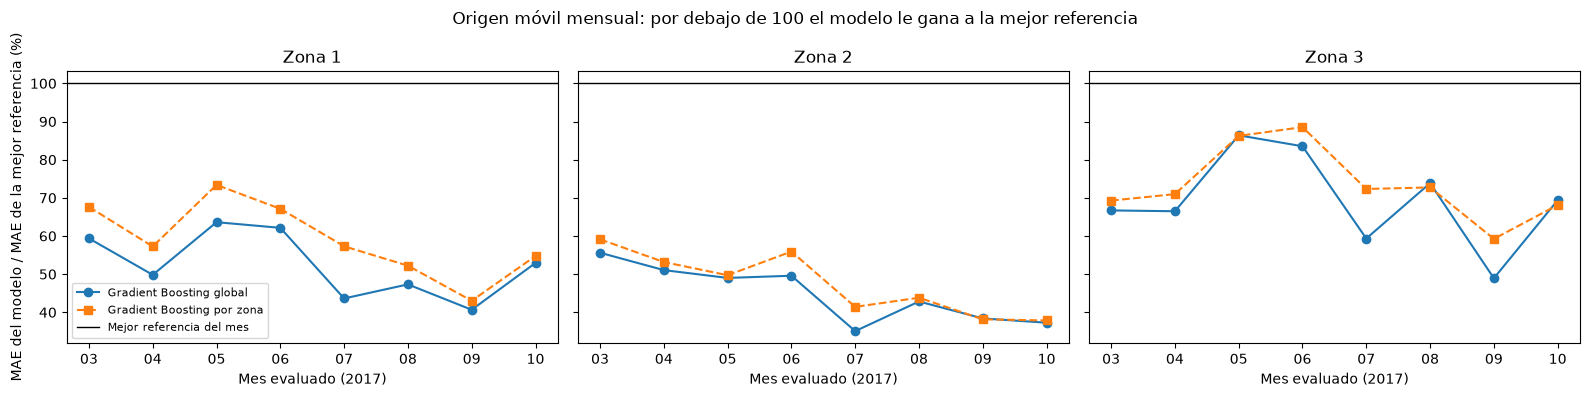

In [12]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for eje, z in zip(ejes, ZONAS):
    d = movil[movil["Zona"] == NOMBRES[z]]
    for m, estilo in zip(METODOS_EVAL, ["-o", "--s", ":^"]):
        eje.plot(d["Mes"].str[5:], 100 * d[m] / d["Mejor referencia"], estilo, label=m)
    eje.axhline(100, color="black", lw=1, label="Mejor referencia del mes")
    eje.set_title(NOMBRES[z])
    eje.set_xlabel("Mes evaluado (2017)")
ejes[0].set_ylabel("MAE del modelo / MAE de la mejor referencia (%)")
ejes[0].legend(fontsize=8)
plt.suptitle("Origen móvil mensual: por debajo de 100 el modelo le gana a la mejor referencia")
plt.tight_layout()
plt.show()

## 8. Prueba final

El modelo se reentrena con entrenamiento y validación (hasta una hora antes de la prueba) y se evalúa una sola
vez en noviembre y diciembre. Además del MAE, RMSE y MAPE:

- **Intervalo de la mejora:** la diferencia de MAE con la mejor referencia, con un intervalo al 95 % por
  *bootstrap* de días (los errores de periodos cercanos están correlacionados).
- **Horas pico** (el periodo que se predice cae entre las 19:00 y las 22:50): MAE y fracción de periodos en los
  que el pronóstico queda más de 5 % por debajo del consumo real, que es el error caro.
- **Reentrenamiento semanal:** como lo haría el centro de control, el modelo se reajusta cada lunes con todo lo
  observado hasta ese momento.

In [13]:
entrenar_final, evaluar_prueba = (lambda d: tramo(d, "desarrollo")), (lambda d: tramo(d, "prueba"))
predicciones_prueba = {m: ajustar_y_predecir(m, entrenar_final, evaluar_prueba) for m in METODOS_EVAL}

# Reentrenamiento semanal del modelo elegido
semanales = {z: [] for z in ZONAS}
lunes = pd.date_range(INICIO_PRUEBA.normalize(), tramo(locales[1], "prueba")["DateTime"].max(), freq="W-MON")
cortes_semana = [INICIO_PRUEBA, *[l for l in lunes if l > INICIO_PRUEBA], pd.Timestamp.max]
for desde, hasta in zip(cortes_semana[:-1], cortes_semana[1:]):
    entrenar = lambda d, desde=desde: d[d["DateTime"] < desde - pd.Timedelta(minutes=10 * HORIZONTE)]
    evaluar = lambda d, desde=desde, hasta=hasta: tramo(d, "prueba")[tramo(d, "prueba")["DateTime"].between(desde, hasta, inclusive="left")]
    for z, pred in ajustar_y_predecir(ELEGIDO, entrenar, evaluar).items():
        semanales[z].append(pred)
predicciones_prueba[f"{ELEGIDO}, reentrenado cada semana"] = {z: np.concatenate(p) for z, p in semanales.items()}

filas, criterios = [], []
for z in ZONAS:
    te = tramo(locales[z], "prueba")
    mejor = mejor_referencia(te)
    pico = np.isin(hora_objetivo(te["DateTime"]), HORAS_PICO)
    metodos = {**{NOMBRES_REF[r]: te[r].to_numpy() for r in REFERENCIAS},
               **{m: p[z] for m, p in predicciones_prueba.items()}}
    mae_mejor = errores(te["real"], te[mejor])["MAE (kW)"]
    mae_mejor_pico = errores(te["real"][pico], te[mejor][pico])["MAE (kW)"]
    for m, pred in metodos.items():
        e = errores(te["real"], pred)
        filas.append({"Zona": NOMBRES[z], "Método": m, **e,
                      "Mejora vs. mejor referencia (%)": 100 * (1 - e["MAE (kW)"] / mae_mejor),
                      "MAE pico (kW)": errores(te["real"][pico], pred[pico])["MAE (kW)"],
                      "Picos subestimados > 5 % (%)": 100 * subestimacion_pico(te["real"], pred, te["DateTime"])})
    pred = predicciones_prueba[ELEGIDO][z]
    dif, bajo, alto = bootstrap_diferencia_mae(te["real"], pred, te[mejor], te["DateTime"], semilla=SEMILLA)
    mae_modelo = errores(te["real"], pred)["MAE (kW)"]
    criterios.append({
        "Zona": NOMBRES[z], "Mejor referencia": NOMBRES_REF[mejor],
        "Diferencia de MAE (kW)": dif, "IC 95 % bajo": bajo, "IC 95 % alto": alto,
        "1. Le gana a la mejor referencia": mae_modelo < mae_mejor,
        "3. Le gana en horas pico": errores(te["real"][pico], pred[pico])["MAE (kW)"] < mae_mejor_pico,
        "Meta: 20 % menos MAE": 100 * (1 - mae_modelo / mae_mejor) >= 20,
    })
prueba = pd.DataFrame(filas).set_index(["Zona", "Método"])
display(prueba.round(2))
criterios = pd.DataFrame(criterios).set_index("Zona")
display(criterios.round(1))

MAE (kW)  RMSE (kW)  MAPE (%)  Mejora vs. mejor referencia (%)  MAE pico (kW)  \
Zona   Método                                                                                                                             
Zona 1 Persistencia                                        1821.29    2504.04      6.29                          -117.31        1489.59   
       Ayer                                                 983.93    1486.60      3.44                           -17.40         660.34   
       Semana pasada                                        838.10    1154.89      2.94                             0.00         652.58   
       Gradient Boosting global                             462.49     672.43      1.63                            44.82         365.47   
       Gradient Boosting por zona                           471.13     670.20      1.66                            43.79         403.85   
       Gradient Boosting global, reentrenado cada semana    446.29     643.78      1.58                            46.75         349.72   
Zona 2 Persistencia                                        1567.42    2182.71      6.78                           -61.00        1260.65   
       Ayer                                                1146.86    1734.65      5.15                           -17.80         910.59   
       Semana pasada                                        973.54    1373.53      4.32                             0.00         832.62   
       Gradient Boosting global                             429.44     613.24      1.91                            55.89         335.09   
       Gradient Boosting por zona                           452.79     656.77      1.98                            53.49         375.41   
       Gradient Boosting global, reentrenado cada semana    415.04     591.76      1.86                            57.37         326.12   
Zona 3 Persistencia                                         950.77    1450.05      8.08                           -31.49         620.33   
       Ayer                                                 723.07    1340.16      6.00                             0.00         553.65   
       Semana pasada                                       1340.32    2199.30     11.13                           -85.37        1086.10   
       Gradient Boosting global                             429.05     726.66      3.63                            40.66         350.56   
       Gradient Boosting por zona                           522.13     921.19      4.30                            27.79         403.28   
       Gradient Boosting global, reentrenado cada semana    415.46     707.45      3.52                            42.54         337.60   

                                                          Picos subestimados > 5 % (%)  
Zona   Método                                                                           
Zona 1 Persistencia                                                               0.00  
       Ayer                                                                       2.80  
       Semana pasada                                                              2.12  
       Gradient Boosting global                                                   0.08  
       Gradient Boosting por zona                                                 0.23  
       Gradient Boosting global, reentrenado cada semana                          0.00  
Zona 2 Persistencia                                                               0.38  
       Ayer                                                                      11.59  
       Semana pasada                                                              6.67  
       Gradient Boosting global                                                   0.23  
       Gradient Boosting por zona                                                 0.08  
       Gradient Boosting global, reentrenado cada semana                          0.08  
Zona 3 Persistencia            

,Mejor referencia,Diferencia de MAE (kW),IC 95 % bajo,IC 95 % alto,1. Le gana a la mejor referencia,3. Le gana en horas pico,Meta: 20 % menos MAE
Zona,,,,,,,
Zona 1,Semana pasada,-375.6,-474.2,-285.8,True,True,True
Zona 2,Semana pasada,-544.1,-727.2,-394.1,True,True,True
Zona 3,Ayer,-294.0,-441.6,-168.9,True,True,True


## 9. Errores desagregados

Con las predicciones de la prueba (por hora y por día de la semana), del origen móvil (por mes, feriados y Ramadán,
que caen fuera de la prueba) y de la validación (antes y después de la transferencia del 25 de octubre).

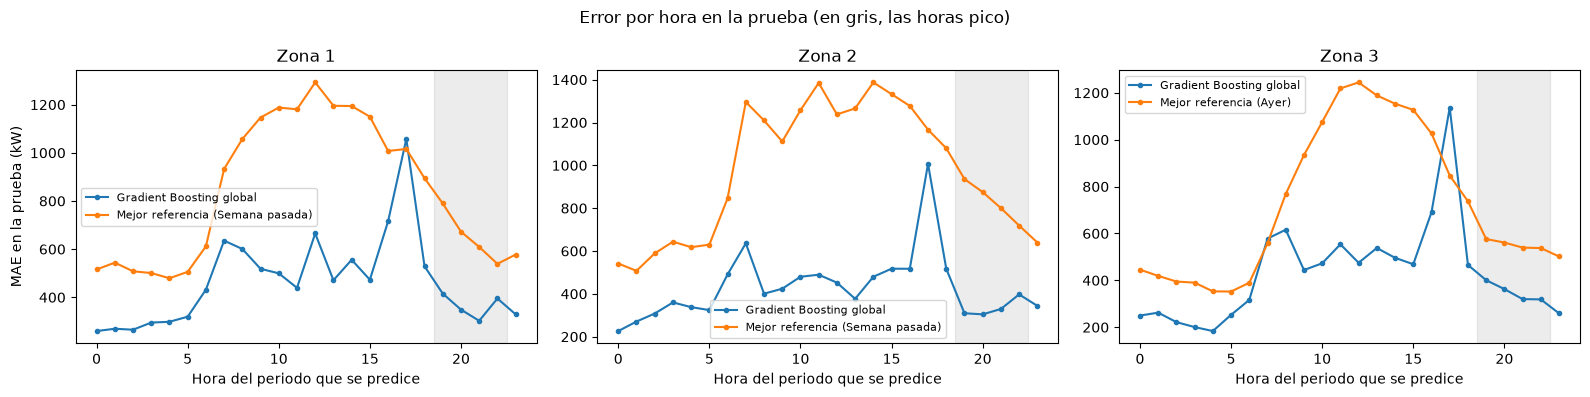

Modelo  Mejor referencia  Mejora (%)
Zona   Días                                               
Zona 1 Fin de semana   406.5             827.2        50.9
       Laborable       483.7             842.2        42.6
Zona 2 Fin de semana   379.1            1126.7        66.4
       Laborable       448.5             915.5        51.0
Zona 3 Fin de semana   482.3             939.9        48.7
       Laborable       408.9             640.9        36.2

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for eje, z in zip(ejes, ZONAS):
    te = tramo(locales[z], "prueba")
    mejor = mejor_referencia(te)
    tabla = mae_por_grupo(te["real"], {ELEGIDO: predicciones_prueba[ELEGIDO][z],
                                       f"Mejor referencia ({NOMBRES_REF[mejor]})": te[mejor]},
                          hora_objetivo(te["DateTime"]))
    tabla.plot(ax=eje, marker="o", ms=3)
    eje.axvspan(min(HORAS_PICO) - 0.5, max(HORAS_PICO) + 0.5, color="grey", alpha=0.15)
    eje.set_title(NOMBRES[z])
    eje.set_xlabel("Hora del periodo que se predice")
    eje.legend(fontsize=8)
ejes[0].set_ylabel("MAE en la prueba (kW)")
plt.suptitle("Error por hora en la prueba (en gris, las horas pico)")
plt.tight_layout()
plt.show()

filas = []
for z in ZONAS:
    te = tramo(locales[z], "prueba")
    mejor = mejor_referencia(te)
    tipo = np.where(te["DateTime"].dt.day_of_week >= 5, "Fin de semana", "Laborable")
    tabla = mae_por_grupo(te["real"], {"Modelo": predicciones_prueba[ELEGIDO][z], "Mejor referencia": te[mejor]}, tipo)
    for grupo, fila in tabla.iterrows():
        filas.append({"Zona": NOMBRES[z], "Días": grupo, **fila, "Mejora (%)": 100 * (1 - fila["Modelo"] / fila["Mejor referencia"])})
display(pd.DataFrame(filas).set_index(["Zona", "Días"]).round(1))

In [15]:
# Origen móvil: feriados y Ramadán (fecha del periodo que se predice)
pm = predicciones_moviles
pm["Mejor referencia"] = np.nan
for (mes, z), idx in pm.groupby([pm["DateTime"].dt.to_period("M"), "zona"]).groups.items():
    d = pm.loc[idx]
    pm.loc[idx, "Mejor referencia"] = d[mejor_referencia(d)]
mayo_junio = pm["DateTime"].dt.month.isin([5, 6])
grupos = {
    "Feriado": np.where(pm["Feriado"] == 1, "Feriado", "Resto"),
    "Ramadán (mayo y junio)": np.where(pm["Ramadan"] == 1, "Ramadán", "Resto de mayo y junio"),
}
filas = []
for nombre, etiqueta in grupos.items():
    filtro = mayo_junio if nombre.startswith("Ramadán") else np.ones(len(pm), bool)
    for z in ZONAS:
        d = pm[filtro & (pm["zona"] == z)]
        tabla = mae_por_grupo(d["real"], {"Modelo": d[ELEGIDO], "Mejor referencia": d["Mejor referencia"]},
                              etiqueta[filtro & (pm["zona"] == z).to_numpy()])
        for grupo, fila in tabla.iterrows():
            filas.append({"Corte": nombre, "Zona": NOMBRES[z], "Grupo": grupo, **fila,
                          "Mejora (%)": 100 * (1 - fila["Modelo"] / fila["Mejor referencia"])})
display(pd.DataFrame(filas).set_index(["Corte", "Zona", "Grupo"]).round(1))

Modelo  Mejor referencia  Mejora (%)
Corte                  Zona   Grupo                                                      
Feriado                Zona 1 Feriado                 984.6            2432.7        59.5
                              Resto                   681.6            1286.0        47.0
                       Zona 2 Feriado                 651.7            1413.7        53.9
                              Resto                   520.9            1181.7        55.9
                       Zona 3 Feriado                 717.1            1323.2        45.8
                              Resto                   473.1             685.6        31.0
Ramadán (mayo y junio) Zona 1 Ramadán                1053.1            1409.8        25.3
                              Resto de mayo y junio   747.1            1448.4        48.4
                       Zona 2 Ramadán                 699.0            1501.7        53.5
                              Resto de mayo y junio   523.7             980.0        46.6
                       Zona 3 Ramadán                 631.1             587.8        -7.4
                              Resto de mayo y junio   420.9             647.3        35.0

**La transferencia del 25 de octubre.** Ese día una parte de la carga de la Zona 1 pasó a la Zona 2 (ver el
notebook 01). La validación cubre del 13 de septiembre al 6 de noviembre, así que se parte en antes y después, con
el modelo entrenado solo con la partición de entrenamiento. Se reporta también la suma de las dos zonas: si el
error de la suma no sube, el modelo pronostica bien la demanda y lo que falla es anticipar la maniobra.

In [16]:
preds_val = candidatos_val[ELEGIDO]
va = {z: tramo(locales[z], "validacion").reset_index(drop=True) for z in ZONAS}
transferencia = pd.Timestamp("2017-10-25")
series = {
    "Zona 1": (va[1]["real"], preds_val[1], va[1]),
    "Zona 2": (va[2]["real"], preds_val[2], va[2]),
    "Zona 1 + Zona 2": (va[1]["real"] + va[2]["real"], preds_val[1] + preds_val[2],
                        va[1][REFERENCIAS] + va[2][REFERENCIAS]),
}
filas = []
for nombre, (real, pred, refs) in series.items():
    fechas = va[1]["DateTime"]
    for etiqueta, filtro in [("Antes (13-sep al 24-oct)", fechas < transferencia),
                             ("Después (26-oct al 6-nov)", fechas >= transferencia + pd.Timedelta(days=1))]:
        r, p, ref = real[filtro], pred[filtro.to_numpy()], refs[filtro]
        mae_refs = {NOMBRES_REF[x]: errores(r, ref[x])["MAE (kW)"] for x in REFERENCIAS}
        mae_modelo = errores(r, p)["MAE (kW)"]
        filas.append({"Serie": nombre, "Periodo": etiqueta, "Modelo": mae_modelo, **mae_refs,
                      "Mejora vs. mejor (%)": 100 * (1 - mae_modelo / min(mae_refs.values()))})
display(pd.DataFrame(filas).set_index(["Serie", "Periodo"]).round(1))

Modelo  Persistencia    Ayer  Semana pasada  Mejora vs. mejor (%)
Serie           Periodo                                                                                     
Zona 1          Antes (13-sep al 24-oct)    571.4        2130.3  1181.4         1170.6                  51.2
                Después (26-oct al 6-nov)   603.5        1867.0   992.0         2313.0                  39.2
Zona 2          Antes (13-sep al 24-oct)    452.4        1323.0  1339.2          978.8                  53.8
                Después (26-oct al 6-nov)   518.2        1581.1  1204.2         1957.8                  57.0
Zona 1 + Zona 2 Antes (13-sep al 24-oct)    825.6        3380.1  2074.6         1765.4                  53.2
                Después (26-oct al 6-nov)   880.9        3374.4  1838.3         1635.8                  46.2

## 10. Diagnóstico: real contra predicho y residuos

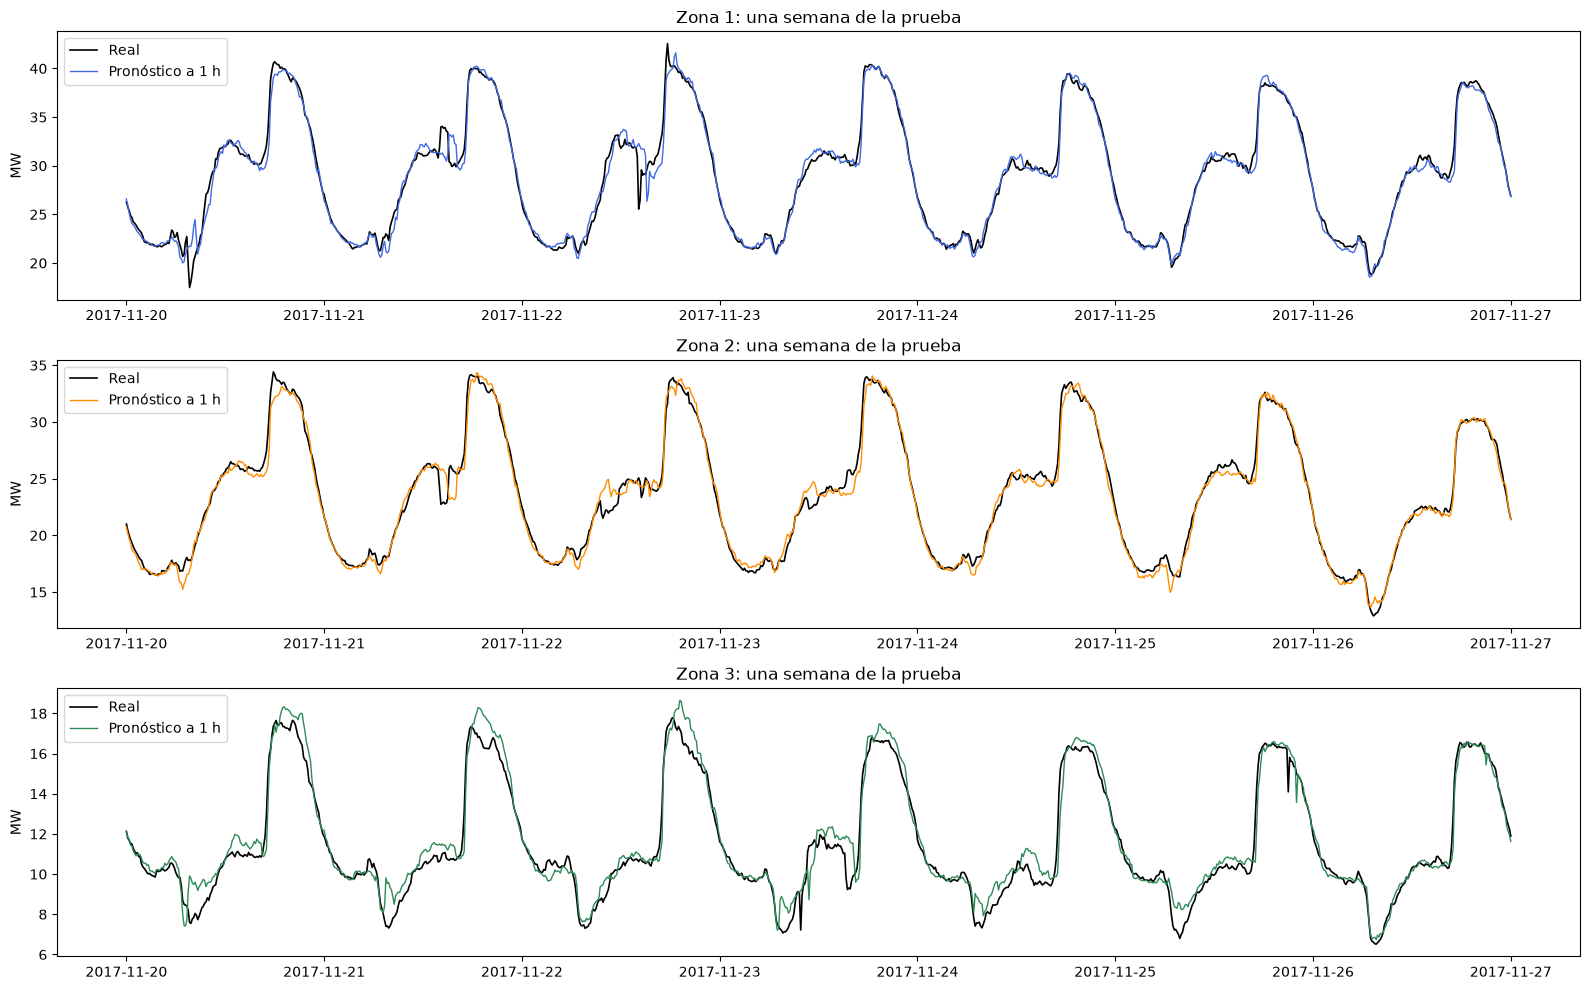

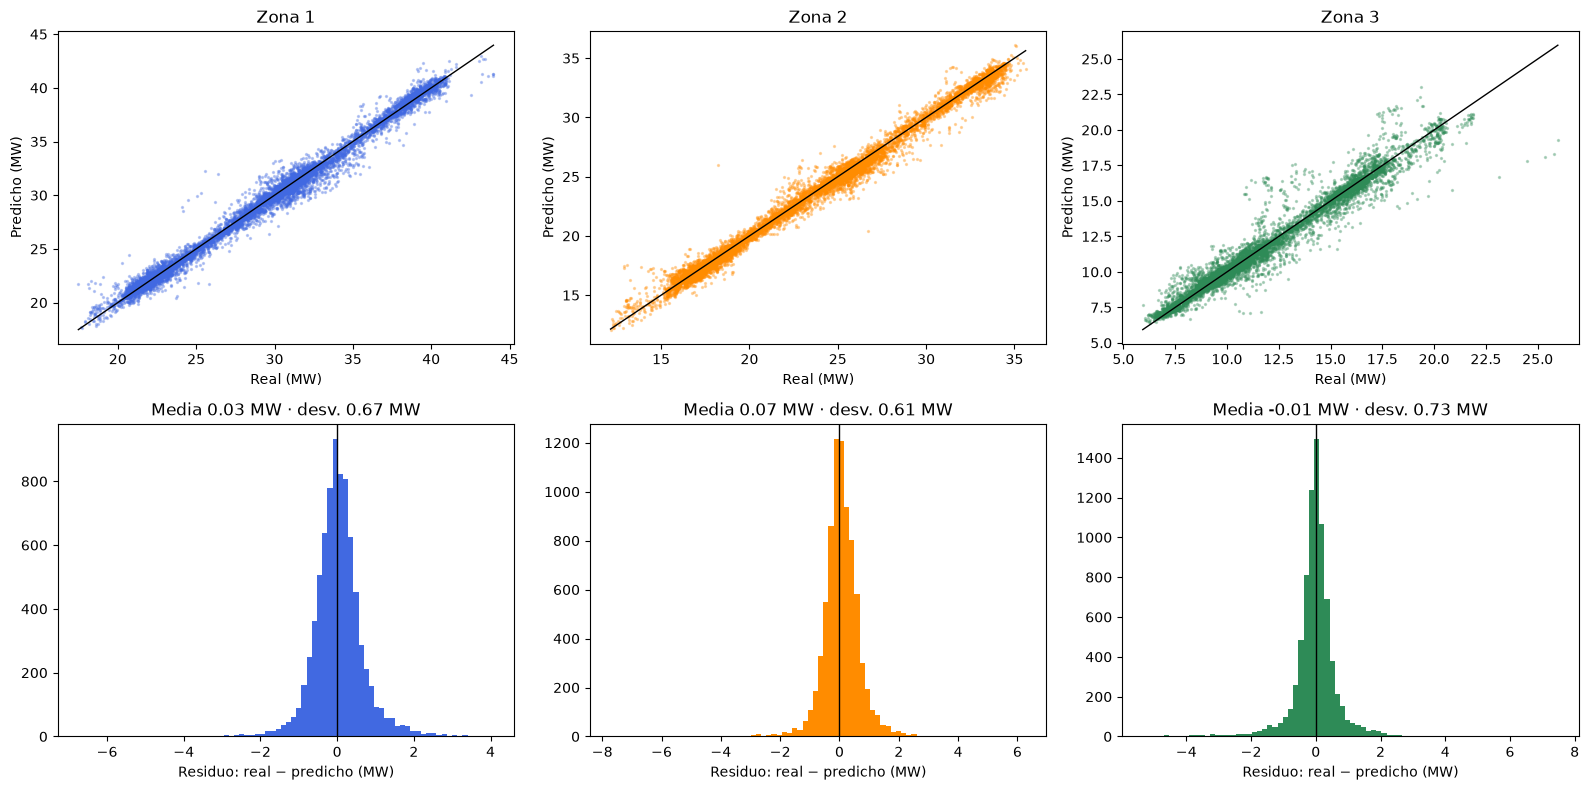

In [17]:
fig, ejes = plt.subplots(3, 1, figsize=(16, 10))
semana = (INICIO_PRUEBA.normalize() + pd.Timedelta(days=14), INICIO_PRUEBA.normalize() + pd.Timedelta(days=21))
for eje, z in zip(ejes, ZONAS):
    te = tramo(locales[z], "prueba").reset_index(drop=True)
    objetivo = te["DateTime"] + pd.Timedelta(minutes=10 * HORIZONTE)  # se grafica en la hora predicha
    filtro = objetivo.between(*semana)
    eje.plot(objetivo[filtro], te["real"][filtro] / 1000, color="black", lw=1.2, label="Real")
    eje.plot(objetivo[filtro], predicciones_prueba[ELEGIDO][z][filtro] / 1000, color=COLORES[z], lw=1,
             label="Pronóstico a 1 h")
    eje.set_ylabel("MW")
    eje.set_title(f"{NOMBRES[z]}: una semana de la prueba")
    eje.legend(loc="upper left")
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(2, 3, figsize=(16, 8))
for i, z in enumerate(ZONAS):
    te = tramo(locales[z], "prueba")
    pred = predicciones_prueba[ELEGIDO][z]
    residuo = (te["real"] - pred) / 1000
    ejes[0, i].scatter(te["real"] / 1000, pred / 1000, s=2, alpha=0.3, color=COLORES[z])
    limites = [te["real"].min() / 1000, te["real"].max() / 1000]
    ejes[0, i].plot(limites, limites, color="black", lw=1)
    ejes[0, i].set(title=NOMBRES[z], xlabel="Real (MW)", ylabel="Predicho (MW)")
    ejes[1, i].hist(residuo, bins=80, color=COLORES[z])
    ejes[1, i].axvline(0, color="black", lw=1)
    ejes[1, i].set(xlabel="Residuo: real − predicho (MW)",
                   title=f"Media {residuo.mean():.2f} MW · desv. {residuo.std():.2f} MW")
plt.tight_layout()
plt.show()

## 11. Importancia de variables

Por **permutación**: cuánto sube el MAE en la validación cuando se desordena una variable, con el modelo elegido
entrenado solo con la partición de entrenamiento. A diferencia de la importancia interna de los árboles, se mide en
kW y sobre datos que el modelo no vio. Se calcula por zona; `media_24h` es la escala que lleva la razón a kW.

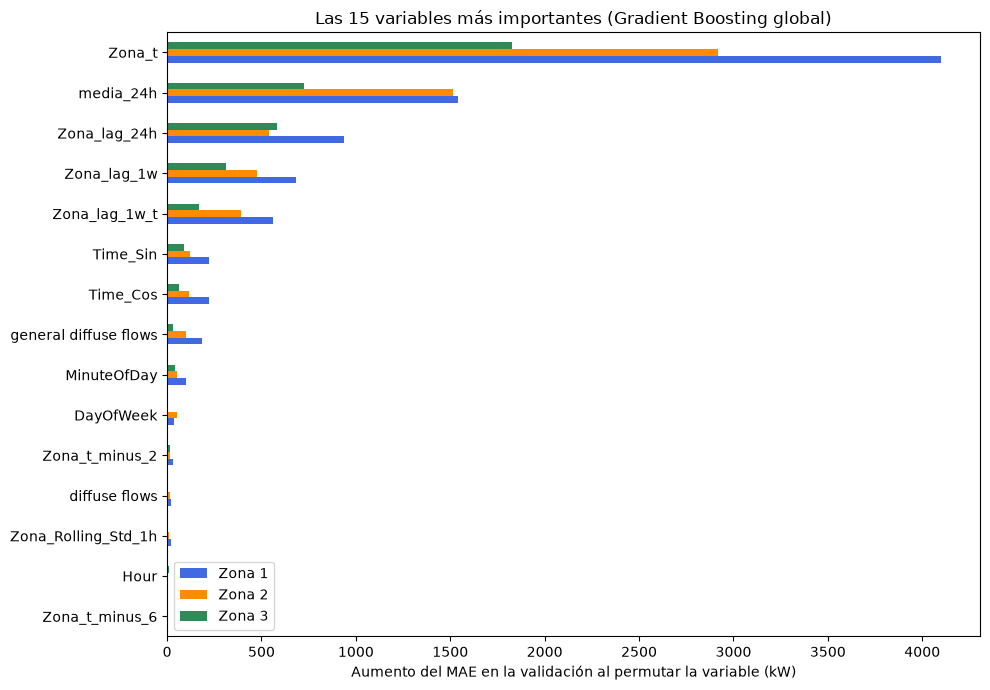

,Zona 1,Zona 2,Zona 3
Zona_t,4100.8,2920.4,1827.9
media_24h,1541.0,1513.9,722.7
Zona_lag_24h,939.3,537.6,581.6
Zona_lag_1w,683.9,475.3,311.9
Zona_lag_1w_t,561.1,389.9,168.8
Time_Sin,223.9,123.5,92.2
Time_Cos,222.6,116.6,60.4
general diffuse flows,184.3,102.4,31.6
MinuteOfDay,100.9,54.4,39.7
DayOfWeek,37.1,54.8,2.3


In [18]:
importancias = {}
for z in ZONAS:
    if ELEGIDO == "Gradient Boosting global":
        modelo = clone(busqueda_global.best_estimator_).fit(tr_g[COLS_GLOBAL], tr_g["real"])
        va_z = tramo(global_, "validacion").query("zona == @z")
        cols = COLS_GLOBAL
    else:
        tr_z, va_z = tramo(locales[z], "entrenamiento"), tramo(locales[z], "validacion")
        cols = columnas_modelo(locales[z])
        modelo = clone(modelo_local(ELEGIDO.removesuffix(" por zona"))).fit(tr_z[cols], tr_z["real"])
    resultado = permutation_importance(modelo, va_z[cols], va_z["real"], scoring="neg_mean_absolute_error",
                                       n_repeats=5, random_state=SEMILLA)
    importancias[NOMBRES[z]] = pd.Series(resultado.importances_mean, index=cols)
importancias = pd.DataFrame(importancias)
importancias = importancias.loc[importancias.mean(axis=1).sort_values(ascending=False).index]

fig, eje = plt.subplots(figsize=(10, 7))
importancias.head(15).iloc[::-1].plot.barh(ax=eje, color=[COLORES[z] for z in ZONAS])
eje.set_xlabel("Aumento del MAE en la validación al permutar la variable (kW)")
eje.set_title(f"Las 15 variables más importantes ({ELEGIDO})")
plt.tight_layout()
plt.show()
display(importancias.round(1))

## 12. Modelo final

El modelo elegido, entrenado con entrenamiento y validación, se guarda en el Drive (`modelos/`) junto con sus
variables y métricas, para la app de Streamlit. Las predicciones de la prueba y las tablas de este notebook quedan
en `reportes/modelado/`.

In [19]:
carpeta_modelos = raiz_datos() / "modelos"
carpeta_reportes = raiz_datos() / "reportes" / "modelado"
carpeta_modelos.mkdir(parents=True, exist_ok=True)
carpeta_reportes.mkdir(parents=True, exist_ok=True)

if ELEGIDO == "Gradient Boosting global":
    finales = {"global": clone(busqueda_global.best_estimator_).fit(tramo(global_, "desarrollo")[COLS_GLOBAL],
                                                                    tramo(global_, "desarrollo")["real"])}
    variables = {"global": COLS_GLOBAL}
else:
    nombre = ELEGIDO.removesuffix(" por zona")
    finales, variables = {}, {}
    for z in ZONAS:
        d = tramo(locales[z], "desarrollo")
        variables[f"zona{z}"] = columnas_modelo(locales[z])
        finales[f"zona{z}"] = clone(modelo_local(nombre)).fit(d[variables[f"zona{z}"]], d["real"])
joblib.dump(finales, carpeta_modelos / "modelo_final.joblib")
metadatos = {
    "modelo": ELEGIDO,
    "variables": variables,
    "entrenado_hasta": str(FIN_DESARROLLO),
    "prueba": json.loads(prueba.loc[(slice(None), ELEGIDO), :].reset_index().to_json(orient="records")),
}
(carpeta_modelos / "modelo_final.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2))

for z in ZONAS:
    te = tramo(locales[z], "prueba")
    salida = te[["DateTime", "real", *REFERENCIAS]].assign(**{m: p[z] for m, p in predicciones_prueba.items()})
    salida.to_csv(carpeta_reportes / f"predicciones_prueba_zona{z}.csv", index=False)
for nombre, tabla in {"busqueda": tabla_busqueda, "comparacion_validacion": comparacion_val,
                      "origen_movil": movil, "prueba": prueba.reset_index(), "importancias": importancias}.items():
    tabla.to_csv(carpeta_reportes / f"{nombre}.csv")
print("Modelo en", carpeta_modelos, "· tablas en", carpeta_reportes)

Modelo en /home/rody/Code/lab/courses/tetouan-power-forecast/data/modelos · tablas en /home/rody/Code/lab/courses/tetouan-power-forecast/data/reportes/modelado


# Conclusiones

(Se completan con los resultados de la corrida.)